# Paso 1: Delimitación Espacial y Descripción de Datos del Distrito de Puno

**Curso:** Estructuras de Datos Avanzadas (EDA) — Unidad 2  
**Área de Estudio:** Distrito de Puno, Provincia y Departamento de Puno, Perú  

### ¿Qué son los archivos de la carpeta `Data/` (`.shp`, `.dbf`, `.shx`, `.prj`, `.cpg`)?
Los datos originales descargados de **OpenStreetMap (Geofabrik — Perú, ~1.5 GB)** vienen en formato estándar **ESRI Shapefile**, donde cada capa geográfica está compuesta obligatoriamente por 5 archivos inseparables:

| Extensión | Nombre / Función | ¿Qué contiene exactamente? |
| :--- | :--- | :--- |
| **`.shp`** | *Shape* (Geometrías) | Coordenadas reales de cada polígono, línea o punto (edificios, calles, parques). |
| **`.dbf`** | *Database File* (Atributos) | La tabla de datos asociada a cada geometría (`osm_id`, `name`, `fclass`, `type`). |
| **`.shx`** | *Shape Index* (Índice) | Índice de acceso directo que enlaza cada geometría del `.shp` con su fila en el `.dbf`. |
| **`.prj`** | *Projection* (Proyección) | Define el Sistema de Referencia de Coordenadas (`WGS 84 / EPSG:4326`). |
| **`.cpg`** | *Code Page* (Codificación) | Indica la codificación de texto (`UTF-8`) para leer tildes y la letra *ñ* correctamente. |

En este cuaderno recortamos únicamente el **Distrito de Puno** y unificamos cada capa en un solo archivo ligero **`.geojson`** dentro de `data_puno/`, dejando además **una vista visual clara de cuántas filas, cuántas variables ($X$) y cuál es la variable objetivo ($y$)** que alimentarán a nuestros 4 modelos de árboles y ensambles.

## 1. Configuración del Entorno y Convenciones Cartográficas

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Rectangle, FancyBboxPatch
import seaborn as sns
import folium

warnings.filterwarnings('ignore')

# Estilo visual limpio y uniforme para todo el proyecto (listo para informe/exposición)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 300,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10,
    'axes.edgecolor': '#bdc3c7',
    'grid.alpha': 0.35
})

# Rutas del proyecto
DIR_DATA_RAW = Path("../Data")
DIR_DATA_PUNO = Path("../data_puno")
DIR_FIGURES = Path("../figures")
DIR_DATA_PUNO.mkdir(parents=True, exist_ok=True)
DIR_FIGURES.mkdir(parents=True, exist_ok=True)

# Convenciones de Sistemas de Referencia de Coordenadas (CRS)
CRS_GEO = "EPSG:4326"      # WGS 84 (grados lat/lon) -> visualización web y GeoJSON
CRS_METRICO = "EPSG:32719" # WGS 84 / UTM Zona 19 Sur (metros) -> áreas y distancias reales

# Cambiar a True solo si deseas volver a recortar desde los shapefiles crudos de 1.5 GB en Data/
FORZAR_EXTRACCION = False

print(f"Carpeta de datos procesados: {DIR_DATA_PUNO.resolve()}")
print(f"Carpeta de figuras (300 DPI): {DIR_FIGURES.resolve()}")

## 2. Extracción del Límite Oficial del Distrito de Puno

En OpenStreetMap para Perú, los límites políticos se distinguen mediante `fclass`:
* `admin_level4`: Departamento / Región
* `admin_level6`: Provincia
* `admin_level8`: **Distrito** — filtramos `name == 'Puno'` y `fclass == 'admin_level8'`.

> **¿Por qué usamos dos CRS (`EPSG:4326` y `EPSG:32719`)?**  
> `EPSG:4326` expresa posiciones en grados geográficos (ideal para Folium/GPS), pero **no sirve para calcular áreas ni distancias en metros**. Por eso proyectamos a **`EPSG:32719` (UTM Zona 19 Sur)** para medir la superficie real de Puno y todas las distancias geométricas del proyecto.

In [ ]:
path_puno_boundary = DIR_DATA_PUNO / "puno_distrito_boundary.geojson"

if path_puno_boundary.exists() and not FORZAR_EXTRACCION:
    puno_distrito = gpd.read_file(path_puno_boundary)
    origen_bdy = "cargado desde caché en data_puno/"
else:
    path_admin = DIR_DATA_RAW / "gis_osm_adminareas_a_free_1.shp"
    gdf_admin = gpd.read_file(path_admin)
    puno_distrito = gdf_admin[
        (gdf_admin['name'] == 'Puno') & (gdf_admin['fclass'] == 'admin_level8')
    ].copy()
    puno_distrito.to_file(path_puno_boundary, driver="GeoJSON")
    origen_bdy = "extraído desde Data/ y guardado en data_puno/"

puno_utm = puno_distrito.to_crs(CRS_METRICO)
area_km2 = puno_utm.geometry.area.iloc[0] / 1e6
perimetro_km = puno_utm.geometry.length.iloc[0] / 1000.0
plaza_armas_geo = Point(-70.0280, -15.8402)
plaza_armas_utm = gpd.GeoSeries([plaza_armas_geo], crs=CRS_GEO).to_crs(CRS_METRICO).iloc[0]

print(f"Polígono oficial: Distrito de {puno_distrito['name'].values[0]} ({origen_bdy})")
print(f"  • OSM ID       : {puno_distrito['osm_id'].values[0]}")
print(f"  • CRS original : {puno_distrito.crs}  -> Proyección métrica: {CRS_METRICO}")
print(f"  • Superficie   : {area_km2:,.2f} km²")
print(f"  • Perímetro    : {perimetro_km:,.2f} km")

Polígono oficial: Distrito de Puno (cargado desde caché en data_puno/)
  • OSM ID       : 1913513
  • CRS original : EPSG:4326  -> Proyección métrica: EPSG:32719
  • Superficie   : 460.41 km²
  • Perímetro    : 118.30 km


## 3. Recorte Espacial Optimizado (*Spatial Index Bounding Box Filter*)

Para no cargar en memoria los ~1.5 GB de todo el Perú, filtramos primero por el rectángulo envolvente (`bbox`) del Distrito de Puno y luego aplicamos la intersección exacta (`intersects`), guardando cada capa como `.geojson` ligero en `data_puno/`.

In [ ]:
puno_geom = puno_distrito.geometry.iloc[0]
puno_bbox = puno_geom.bounds  # (minx, miny, maxx, maxy) en EPSG:4326

def cargar_o_recortar(nombre_shp, nombre_geojson):
    ruta_out = DIR_DATA_PUNO / nombre_geojson
    if ruta_out.exists() and not FORZAR_EXTRACCION:
        return gpd.read_file(ruta_out)
    print(f"Recortando desde Data/: {nombre_shp} -> {nombre_geojson} ...")
    gdf = gpd.read_file(DIR_DATA_RAW / nombre_shp, bbox=puno_bbox)
    gdf_puno = gdf[gdf.intersects(puno_geom)].copy()
    gdf_puno.to_file(ruta_out, driver="GeoJSON")
    return gdf_puno

# 4 Capas Principales
gdf_buildings = cargar_o_recortar("gis_osm_buildings_a_free_1.shp", "puno_buildings.geojson")
gdf_landuse   = cargar_o_recortar("gis_osm_landuse_a_free_1.shp",   "puno_landuse.geojson")
gdf_roads     = cargar_o_recortar("gis_osm_roads_free_1.shp",       "puno_roads.geojson")
gdf_pois      = cargar_o_recortar("gis_osm_pois_free_1.shp",        "puno_pois.geojson")

# 4 Capas Complementarias (contexto hídrico, transporte y POIs poligonales)
gdf_pois_a    = cargar_o_recortar("gis_osm_pois_a_free_1.shp",      "puno_pois_a.geojson")
gdf_transport = cargar_o_recortar("gis_osm_transport_free_1.shp",   "puno_transport.geojson")
gdf_water_a   = cargar_o_recortar("gis_osm_water_a_free_1.shp",     "puno_water_a.geojson")
gdf_waterways = cargar_o_recortar("gis_osm_waterways_free_1.shp",   "puno_waterways.geojson")

# Proyección métrica para estadísticas descriptivas exactas
b_utm   = gdf_buildings.to_crs(CRS_METRICO)
lu_utm  = gdf_landuse.to_crs(CRS_METRICO)
rd_utm  = gdf_roads.to_crs(CRS_METRICO)
p_utm   = gdf_pois.to_crs(CRS_METRICO)
pa_utm  = gdf_pois_a.to_crs(CRS_METRICO)
tr_utm  = gdf_transport.to_crs(CRS_METRICO)
wa_utm  = gdf_water_a.to_crs(CRS_METRICO)
ww_utm  = gdf_waterways.to_crs(CRS_METRICO)

print("Todas las capas del Distrito de Puno cargadas y proyectadas correctamente.")

Todas las capas del Distrito de Puno cargadas y proyectadas correctamente.


## 4. Inventario de Capas Crudas y Muestra Real de los Datos de Puno

Primero revisamos el inventario de las capas vectoriales recortadas para Puno y **cómo vienen estructuradas sus columnas originales en OpenStreetMap** antes de construir las variables de Machine Learning.

In [ ]:
resumen_capas = pd.DataFrame([
    {
        "Capa": "Límite Distrital", "Archivo GeoJSON": "puno_distrito_boundary.geojson",
        "Geometría": "Polígono", "Registros": len(puno_distrito),
        "Métrica Espacial": f"{area_km2:,.2f} km²",
        "Rol en el Proyecto": "Máscara administrativa oficial"
    },
    {
        "Capa": "Edificaciones (Micro)", "Archivo GeoJSON": "puno_buildings.geojson",
        "Geometría": "Polígonos", "Registros": len(gdf_buildings),
        "Métrica Espacial": f"{b_utm.geometry.area.sum()/1e6:.2f} km² construidos",
        "Rol en el Proyecto": "Unidad de análisis — Nivel Micro (Paso 2)"
    },
    {
        "Capa": "Uso de Suelo (Macro)", "Archivo GeoJSON": "puno_landuse.geojson",
        "Geometría": "Polígonos", "Registros": len(gdf_landuse),
        "Métrica Espacial": f"{lu_utm.geometry.area.sum()/1e6:.2f} km² cubiertos",
        "Rol en el Proyecto": "Etiquetas base — Nivel Macro (Paso 3)"
    },
    {
        "Capa": "Red Vial", "Archivo GeoJSON": "puno_roads.geojson",
        "Geometría": "Líneas", "Registros": len(gdf_roads),
        "Métrica Espacial": f"{rd_utm.geometry.length.sum()/1000:,.1f} km totales",
        "Rol en el Proyecto": "Accesibilidad y densidad vial (Micro y Macro)"
    },
    {
        "Capa": "POIs Puntuales", "Archivo GeoJSON": "puno_pois.geojson",
        "Geometría": "Puntos", "Registros": len(gdf_pois),
        "Métrica Espacial": f"{gdf_pois['fclass'].nunique()} categorías",
        "Rol en el Proyecto": "Servicios y comercio con cKDTree (Micro y Macro)"
    },
    {
        "Capa": "POIs Poligonales", "Archivo GeoJSON": "puno_pois_a.geojson",
        "Geometría": "Polígonos", "Registros": len(gdf_pois_a),
        "Métrica Espacial": f"{gdf_pois_a['fclass'].nunique()} categorías",
        "Rol en el Proyecto": "Equipamiento y áreas verdes — Nivel Macro"
    },
    {
        "Capa": "Transporte", "Archivo GeoJSON": "puno_transport.geojson",
        "Geometría": "Puntos", "Registros": len(gdf_transport),
        "Métrica Espacial": f"{gdf_transport['fclass'].nunique()} tipos",
        "Rol en el Proyecto": "Proximidad a paraderos/terminales (Nivel Macro)"
    },
    {
        "Capa": "Cuerpos de Agua", "Archivo GeoJSON": "puno_water_a.geojson",
        "Geometría": "Polígonos", "Registros": len(gdf_water_a),
        "Métrica Espacial": "Lago Titicaca / lagunas",
        "Rol en el Proyecto": "Distancia al borde lacustre (Nivel Macro)"
    },
    {
        "Capa": "Quebradas y Ríos", "Archivo GeoJSON": "puno_waterways.geojson",
        "Geometría": "Líneas", "Registros": len(gdf_waterways),
        "Métrica Espacial": f"{ww_utm.geometry.length.sum()/1000:,.1f} km",
        "Rol en el Proyecto": "Contexto hídrico y relieve (Nivel Macro)"
    }
])

display(resumen_capas)

# Vista rápida de cómo llegan los datos crudos desde OpenStreetMap (columnas originales)
print("\nMuestra de datos crudos — puno_buildings.geojson (primeras 5 filas con nombre o tipo):")
muestra_b_cruda = gdf_buildings[gdf_buildings['name'].notna() | gdf_buildings['type'].notna()][
    ['osm_id', 'code', 'fclass', 'name', 'type']
].head(5).copy()
muestra_b_cruda['geometria'] = 'Polygon (UTM/WGS84)'
display(muestra_b_cruda)

print("\nMuestra de datos crudos — puno_landuse.geojson (primeras 5 filas):")
muestra_lu_cruda = gdf_landuse[['osm_id', 'code', 'fclass', 'name']].head(5).copy()
muestra_lu_cruda['area_m2'] = lu_utm.geometry.area.head(5).round(1).values
display(muestra_lu_cruda)

,Capa,Archivo GeoJSON,Geometría,Registros,Métrica Espacial,Rol en el Proyecto
0,Límite Distrital,puno_distrito_boundary.geojson,Polígono,1,460.41 km²,Máscara administrativa oficial
1,Edificaciones (Micro),puno_buildings.geojson,Polígonos,652,0.30 km² construidos,Unidad de análisis — Nivel Micro (Paso 2)
2,Uso de Suelo (Macro),puno_landuse.geojson,Polígonos,273,41.35 km² cubiertos,Etiquetas base — Nivel Macro (Paso 3)
3,Red Vial,puno_roads.geojson,Líneas,4276,"1,114.2 km totales",Accesibilidad y densidad vial (Micro y Macro)
4,POIs Puntuales,puno_pois.geojson,Puntos,935,64 categorías,Servicios y comercio con cKDTree (Micro y Macro)
5,POIs Poligonales,puno_pois_a.geojson,Polígonos,330,31 categorías,Equipamiento y áreas verdes — Nivel Macro
6,Transporte,puno_transport.geojson,Puntos,48,5 tipos,Proximidad a paraderos/terminales (Nivel Macro)
7,Cuerpos de Agua,puno_water_a.geojson,Polígonos,9,Lago Titicaca / lagunas,Distancia al borde lacustre (Nivel Macro)
8,Quebradas y Ríos,puno_waterways.geojson,Líneas,30,39.7 km,Contexto hídrico y relieve (Nivel Macro)



Muestra de datos crudos — puno_buildings.geojson (primeras 5 filas con nombre o tipo):


,osm_id,code,fclass,name,type,geometria
2,225903400,1500,building,Iglesia de San Juan,church,Polygon (UTM/WGS84)
9,245233060,1500,building,Terminal Terrestre de Puno,NaN,Polygon (UTM/WGS84)
10,245233061,1500,building,Mercado Central,NaN,Polygon (UTM/WGS84)
14,255732549,1500,building,Iglesia Biblica Bautista,NaN,Polygon (UTM/WGS84)
15,315213481,1500,building,Condor,NaN,Polygon (UTM/WGS84)



Muestra de datos crudos — puno_landuse.geojson (primeras 5 filas):


,osm_id,code,fclass,name,area_m2
0,23782585,7202,park,Parque Pino,1934.7
1,123162130,7206,cemetery,Cementerio Central de Laykakota,14341.3
2,189172773,7202,park,Óvalo Ramón Castilla,2663.6
3,189172774,7202,park,Dante Nava,1052.8
4,234953768,7202,park,NaN,1471.8


## 5. Ficha Visual de Nuestras Bases de Datos de Modelado (¿Cuántos datos, cuántas variables y cuál es la variable objetivo $y$?)

Esta sección responde de forma visual y directa a las preguntas clave de dominio de datos para árboles de decisión:
* **¿Cuántos registros (filas) tenemos en Puno?**
* **¿Cuántas variables predictoras ($X$) entran a los modelos?**
* **¿Cuál es exactamente nuestra variable objetivo ($y$) y cuántas clases tiene?**

A continuación se presenta la **ficha gráfica comparativa** de ambos datasets (`Nivel Micro` y `Nivel Macro`) seguida de una **vista real de las tablas de datos** con la variable objetivo ($y$) resaltada.

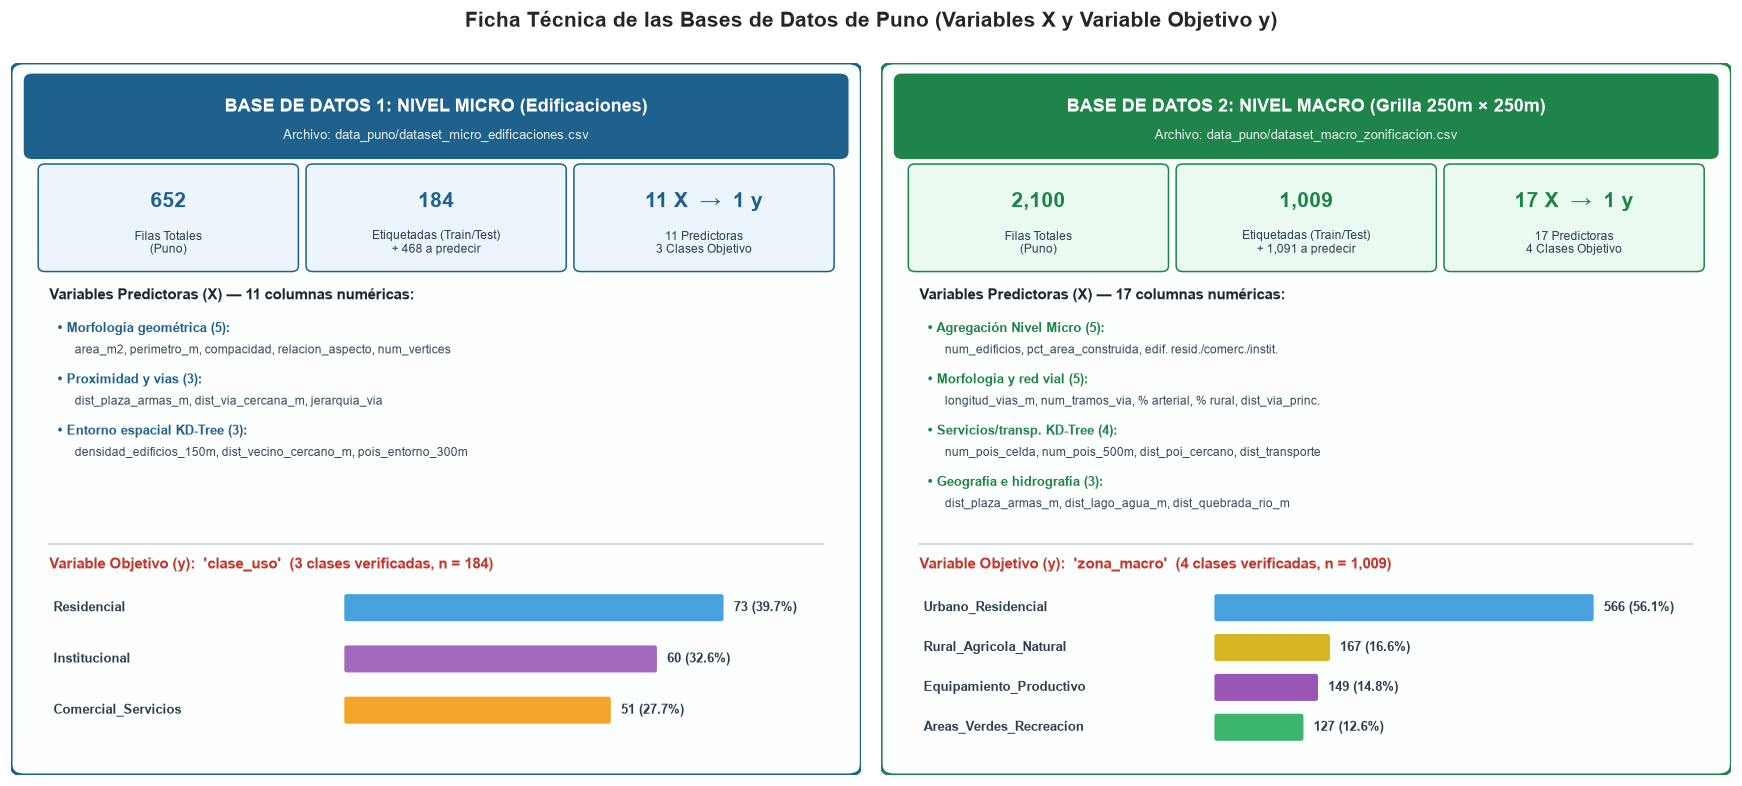

Figura guardada en: figures/01_esquema_datasets_puno.png


In [ ]:
# Cargar los datasets tabulares de Puno generados a partir de las capas GeoJSON
df_micro = pd.read_csv(DIR_DATA_PUNO / "dataset_micro_edificaciones.csv")
df_macro = pd.read_csv(DIR_DATA_PUNO / "dataset_macro_zonificacion.csv")

FEATURES_MICRO = [
    'area_m2', 'perimetro_m', 'compacidad', 'relacion_aspecto', 'num_vertices',
    'dist_plaza_armas_m', 'dist_via_cercana_m', 'jerarquia_via',
    'densidad_edificios_150m', 'dist_vecino_cercano_m', 'pois_entorno_300m'
]
FEATURES_MACRO = [
    'num_edificios', 'pct_area_construida',
    'edificios_residenciales', 'edificios_comerciales', 'edificios_institucionales',
    'longitud_vias_m', 'num_tramos_via', 'pct_vias_arteriales', 'pct_vias_rurales_peat', 'dist_via_principal_m',
    'num_pois_celda', 'num_pois_500m', 'dist_poi_cercano_m', 'dist_transporte_m',
    'dist_plaza_armas_m', 'dist_lago_agua_m', 'dist_quebrada_rio_m'
]

# --- INFOGRAFÍA / FICHA VISUAL DE AMBOS DATASETS (MICRO VS. MACRO) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 7.2))
fig.patch.set_facecolor('white')

configs = [
    {
        'ax': axes[0],
        'titulo': "BASE DE DATOS 1: NIVEL MICRO (Edificaciones)",
        'subtitulo': "Archivo: data_puno/dataset_micro_edificaciones.csv",
        'color_hdr': '#1f618d',
        'color_bg': '#ebf5fb',
        'total_filas': len(df_micro),
        'etiquetadas': int(df_micro['clase_uso'].notna().sum()),
        'sin_etiqueta': int(df_micro['clase_uso'].isna().sum()),
        'n_features': len(FEATURES_MICRO),
        'target_col': 'clase_uso',
        'n_clases': 3,
        'grupos_vars': [
            ("Morfología geométrica (5):", "area_m2, perimetro_m, compacidad, relacion_aspecto, num_vertices"),
            ("Proximidad y vías (3):", "dist_plaza_armas_m, dist_via_cercana_m, jerarquia_via"),
            ("Entorno espacial KD-Tree (3):", "densidad_edificios_150m, dist_vecino_cercano_m, pois_entorno_300m")
        ],
        'clases': df_micro['clase_uso'].value_counts(),
        'colores_clases': {'Residencial': '#3498db', 'Institucional': '#9b59b6', 'Comercial_Servicios': '#f39c12'}
    },
    {
        'ax': axes[1],
        'titulo': "BASE DE DATOS 2: NIVEL MACRO (Grilla 250m × 250m)",
        'subtitulo': "Archivo: data_puno/dataset_macro_zonificacion.csv",
        'color_hdr': '#1e8449',
        'color_bg': '#eafaf1',
        'total_filas': len(df_macro),
        'etiquetadas': int(df_macro['zona_macro'].notna().sum()),
        'sin_etiqueta': int(df_macro['zona_macro'].isna().sum()),
        'n_features': len(FEATURES_MACRO),
        'target_col': 'zona_macro',
        'n_clases': 4,
        'grupos_vars': [
            ("Agregación Nivel Micro (5):", "num_edificios, pct_area_construida, edif. resid./comerc./instit."),
            ("Morfología y red vial (5):", "longitud_vias_m, num_tramos_via, % arterial, % rural, dist_via_princ."),
            ("Servicios/transp. KD-Tree (4):", "num_pois_celda, num_pois_500m, dist_poi_cercano, dist_transporte"),
            ("Geografía e hidrografía (3):", "dist_plaza_armas_m, dist_lago_agua_m, dist_quebrada_rio_m")
        ],
        'clases': df_macro['zona_macro'].value_counts(),
        'colores_clases': {
            'Urbano_Residencial': '#3498db', 'Rural_Agricola_Natural': '#d4ac0d',
            'Equipamiento_Productivo': '#8e44ad', 'Areas_Verdes_Recreacion': '#27ae60'
        }
    }
]

for cfg in configs:
    ax = cfg['ax']
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off')

    # Marco exterior
    ax.add_patch(FancyBboxPatch((0.15, 0.15), 9.7, 9.7, boxstyle="round,pad=0.15",
                                facecolor='#fdfefe', edgecolor=cfg['color_hdr'], linewidth=2.0))
    # Encabezado
    ax.add_patch(FancyBboxPatch((0.25, 8.75), 9.5, 1.0, boxstyle="round,pad=0.1",
                                facecolor=cfg['color_hdr'], edgecolor='none'))
    ax.text(5.0, 9.38, cfg['titulo'], color='white', fontsize=11.5, fontweight='bold', ha='center', va='center')
    ax.text(5.0, 8.98, cfg['subtitulo'], color='#eaecee', fontsize=8.5, ha='center', va='center')

    # 3 KPIs numéricos grandes
    kpis = [
        (1.85, f"{cfg['total_filas']:,}", "Filas Totales\n(Puno)"),
        (5.00, f"{cfg['etiquetadas']:,}", "Etiquetadas (Train/Test)\n+ " + f"{cfg['sin_etiqueta']:,} a predecir"),
        (8.15, f"{cfg['n_features']} X  →  1 y", f"{cfg['n_features']} Predictoras\n{cfg['n_clases']} Clases Objetivo")
    ]
    for x_pos, val, desc in kpis:
        ax.add_patch(FancyBboxPatch((x_pos - 1.45, 7.15), 2.9, 1.35, boxstyle="round,pad=0.08",
                                    facecolor=cfg['color_bg'], edgecolor=cfg['color_hdr'], linewidth=1.0))
        ax.text(x_pos, 8.05, val, color=cfg['color_hdr'], fontsize=13.5, fontweight='bold', ha='center', va='center')
        ax.text(x_pos, 7.48, desc, color='#2c3e50', fontsize=8.0, ha='center', va='center', linespacing=1.2)

    # Bloque de Variables Predictoras (X)
    ax.text(0.45, 6.68, f"Variables Predictoras (X) — {cfg['n_features']} columnas numéricas:",
            fontsize=9.8, fontweight='bold', color='#1c2833')
    y_cursor = 6.22
    for grp_titulo, grp_vars in cfg['grupos_vars']:
        ax.text(0.55, y_cursor, f"• {grp_titulo}", fontsize=8.5, fontweight='bold', color=cfg['color_hdr'])
        ax.text(0.75, y_cursor - 0.30, grp_vars, fontsize=7.9, color='#34495e')
        y_cursor -= 0.72

    # Separador y Variable Objetivo (y)
    ax.plot([0.45, 9.55], [3.25, 3.25], color='#d5d8dc', linewidth=1.2)
    ax.text(0.45, 2.90, f"Variable Objetivo (y):  '{cfg['target_col']}'  ({cfg['n_clases']} clases verificadas, n = {cfg['etiquetadas']:,})",
            fontsize=9.8, fontweight='bold', color='#c0392b')

    # Mini barras horizontales de distribución de la variable objetivo
    clases = cfg['clases']
    max_val = clases.max()
    y_bar = 2.35
    step_bar = 0.56 if len(clases) == 4 else 0.72
    for cls_name, cnt in clases.items():
        pct = cnt / cfg['etiquetadas'] * 100
        bar_w = (cnt / max_val) * 4.4
        c_bar = cfg['colores_clases'].get(cls_name, '#7f8c8d')
        ax.text(0.50, y_bar, cls_name, fontsize=8.5, fontweight='bold', color='#2c3e50', va='center')
        ax.add_patch(FancyBboxPatch((3.95, y_bar - 0.16), bar_w, 0.32, boxstyle="round,pad=0.03",
                                    facecolor=c_bar, edgecolor='none', alpha=0.9))
        ax.text(3.95 + bar_w + 0.15, y_bar, f"{cnt} ({pct:.1f}%)", fontsize=8.5, fontweight='bold', color='#2c3e50', va='center')
        y_bar -= step_bar

plt.suptitle("Ficha Técnica de las Bases de Datos de Puno (Variables X y Variable Objetivo y)", fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "01_esquema_datasets_puno.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/01_esquema_datasets_puno.png")

In [ ]:
# --- TABLAS VISUALES REALES DE AMBAS BASES DE DATOS (CON VARIABLE OBJETIVO RESALTADA) ---
print("=" * 95)
print(f"TABLA 1 — NIVEL MICRO (Edificaciones de Puno): {df_micro.shape[0]} filas × {len(FEATURES_MICRO)} variables X + 1 variable objetivo 'clase_uso'")
print("=" * 95)

muestra_micro = (
    df_micro.dropna(subset=['clase_uso'])
    .groupby('clase_uso', group_keys=False)
    .head(2)
    [['name', 'area_m2', 'perimetro_m', 'compacidad', 'dist_plaza_armas_m',
      'dist_via_cercana_m', 'densidad_edificios_150m', 'pois_entorno_300m', 'clase_uso']]
    .copy()
)
muestra_micro['name'] = muestra_micro['name'].fillna('Sin nombre (vivienda)')
num_cols_mi = ['area_m2', 'perimetro_m', 'compacidad', 'dist_plaza_armas_m', 'dist_via_cercana_m']
muestra_micro[num_cols_mi] = muestra_micro[num_cols_mi].round(2)

display(
    muestra_micro.style
    .set_caption("Ejemplo real de filas etiquetadas — Nivel Micro (columna resaltada = Variable Objetivo y)")
    .set_properties(subset=['clase_uso'], **{'background-color': '#d4efdf', 'color': '#145a32', 'font-weight': 'bold'})
    .format({c: "{:.2f}" for c in num_cols_mi})
)

print("\n" + "=" * 95)
print(f"TABLA 2 — NIVEL MACRO (Grilla 250m×250m de Puno): {df_macro.shape[0]} filas × {len(FEATURES_MACRO)} variables X + 1 variable objetivo 'zona_macro'")
print("=" * 95)

muestra_macro = (
    df_macro.dropna(subset=['zona_macro'])
    .groupby('zona_macro', group_keys=False)
    .head(2)
    [['cell_id', 'num_edificios', 'pct_area_construida', 'longitud_vias_m',
      'pct_vias_arteriales', 'num_pois_500m', 'dist_plaza_armas_m', 'dist_lago_agua_m', 'zona_macro']]
    .copy()
)
num_cols_ma = ['pct_area_construida', 'longitud_vias_m', 'pct_vias_arteriales', 'dist_plaza_armas_m', 'dist_lago_agua_m']
muestra_macro[num_cols_ma] = muestra_macro[num_cols_ma].round(2)

display(
    muestra_macro.style
    .set_caption("Ejemplo real de filas etiquetadas — Nivel Macro (columna resaltada = Variable Objetivo y)")
    .set_properties(subset=['zona_macro'], **{'background-color': '#d6eaf8', 'color': '#1b4f72', 'font-weight': 'bold'})
    .format({c: "{:.2f}" for c in num_cols_ma})
)

TABLA 1 — NIVEL MICRO (Edificaciones de Puno): 652 filas × 11 variables X + 1 variable objetivo 'clase_uso'


,name,area_m2,perimetro_m,compacidad,dist_plaza_armas_m,dist_via_cercana_m,densidad_edificios_150m,pois_entorno_300m,clase_uso
2,Iglesia de San Juan,1249.99,205.46,0.37,268.81,6.02,1,193,Institucional
9,Terminal Terrestre de Puno,3293.20,401.51,0.26,1227.39,5.53,11,18,Comercial_Servicios
10,Mercado Central,2858.43,223.21,0.72,338.44,3.09,4,200,Comercial_Servicios
14,Iglesia Biblica Bautista,834.88,134.30,0.58,1024.28,3.08,2,34,Institucional
230,Sin nombre (vivienda),96.95,40.85,0.73,924.61,4.03,21,21,Residencial
231,Sin nombre (vivienda),86.67,37.79,0.76,926.82,4.33,23,23,Residencial



TABLA 2 — NIVEL MACRO (Grilla 250m×250m de Puno): 2100 filas × 17 variables X + 1 variable objetivo 'zona_macro'


,cell_id,num_edificios,pct_area_construida,longitud_vias_m,pct_vias_arteriales,num_pois_500m,dist_plaza_armas_m,dist_lago_agua_m,zona_macro
249,3223,0,0.00,308.23,0.87,0,6144.51,6961.38,Urbano_Residencial
274,3322,0,0.00,30.40,0.00,0,5653.90,6618.90,Urbano_Residencial
390,3792,0,0.00,0.00,0.00,0,7621.97,7972.07,Equipamiento_Productivo
391,3793,0,0.00,0.00,0.00,0,7417.36,7808.79,Equipamiento_Productivo
537,4296,0,0.00,0.00,0.00,0,3519.22,4211.83,Rural_Agricola_Natural
571,4385,0,0.00,504.91,0.00,1,3303.39,3967.65,Rural_Agricola_Natural
602,4464,0,0.00,191.38,0.00,0,2623.96,3836.98,Areas_Verdes_Recreacion
611,4474,0,0.00,1636.58,0.00,5,3238.46,3790.86,Areas_Verdes_Recreacion


## 6. Radiografía Descriptiva de los Datos Crudos de Puno (OpenStreetMap)

Este panel 2×2 resume visualmente los **datos crudos originales de Puno** y expone los **dos desafíos reales** que motivan el uso de árboles de decisión y ensambles en los Pasos 2 y 3:
1. **Panel A (`buildings`):** El **80.5% de las edificaciones (525 de 652)** no tiene etiqueta `type` en OSM → por eso entrenamos modelos supervisados en el **Paso 2**.
2. **Panel B (`landuse`):** Aunque `grass` (110) y `park` (86) tienen muchos polígonos diminutos, **`residential` concentra `33.53 km²` en solo 25 polígonos** → por eso estandarizamos el territorio con una **Grilla Espacial de 250m × 250m en el Paso 3**.
3. **Paneles C y D (`roads` y `pois`):** Muestran el detalle de la red vial (`1,114 km`) y los servicios urbanos (`935` POIs) que alimentan nuestras variables espaciales con `cKDTree`.

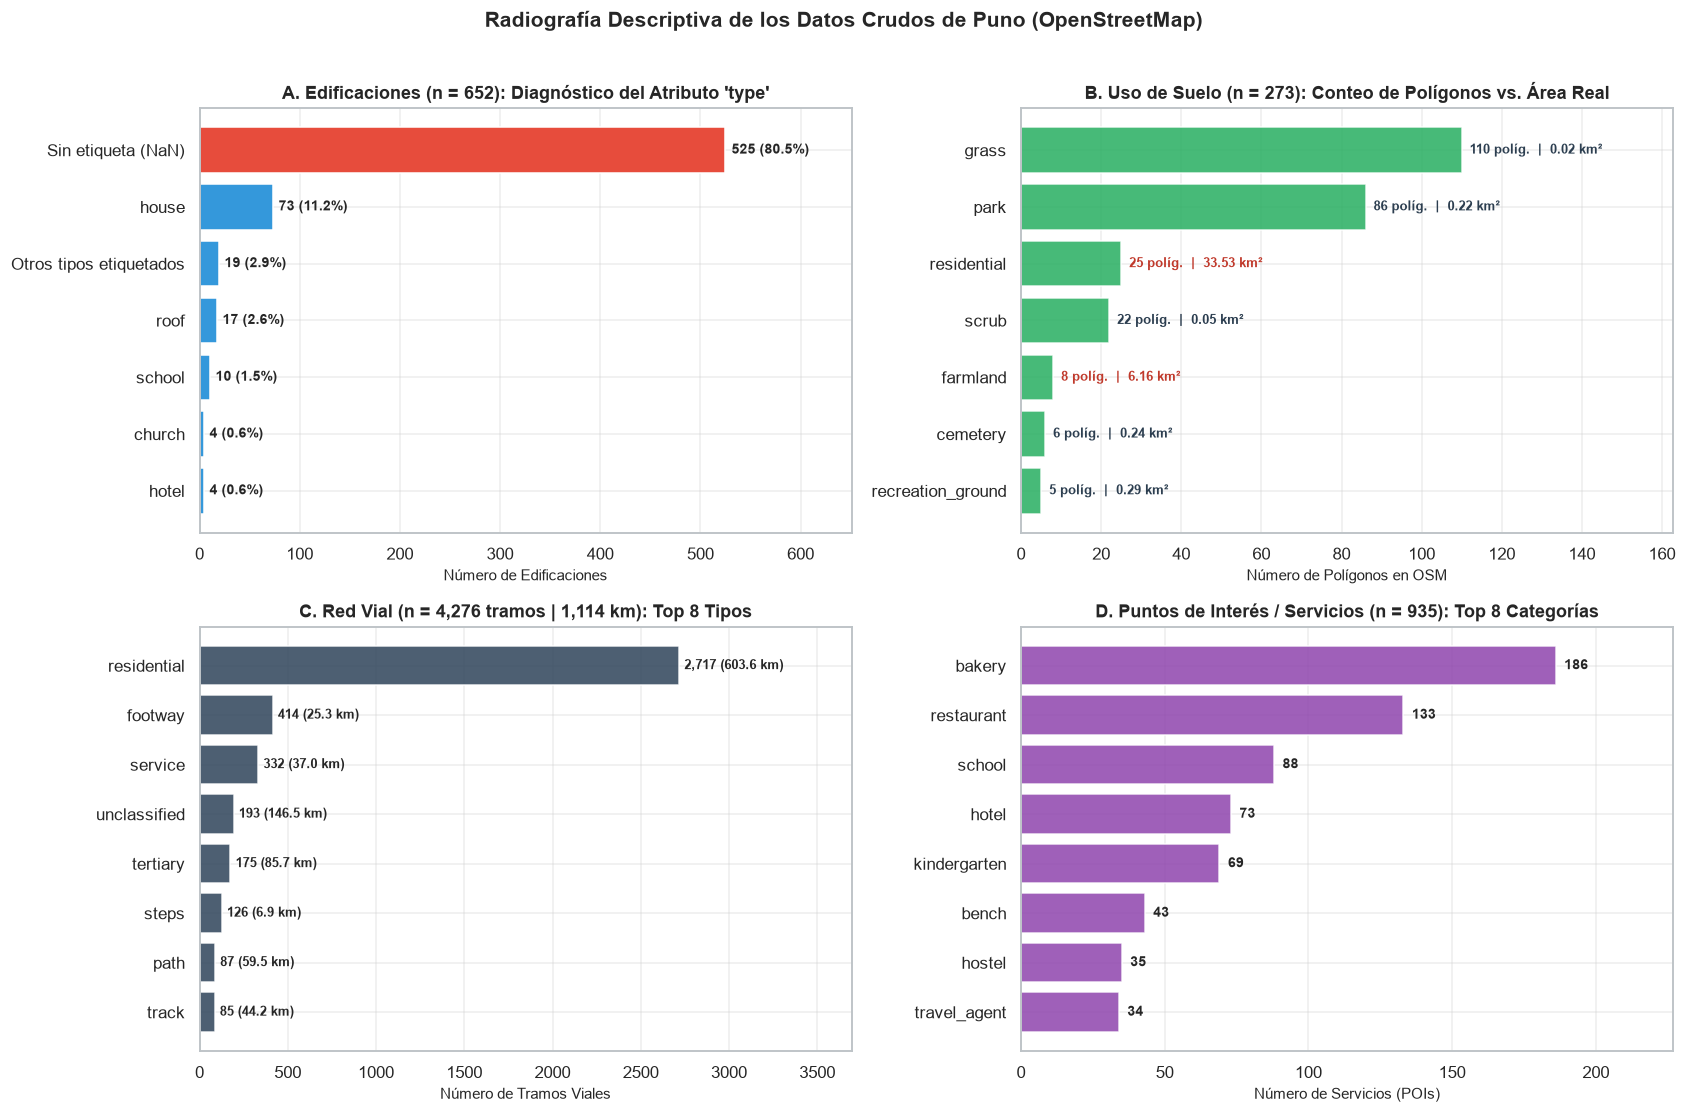

Figura guardada en: figures/01_radiografia_datos_puno.png


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15.5, 10))

# --- PANEL A: Edificaciones (Completitud de etiqueta 'type') ---
b_types = gdf_buildings['type'].fillna('Sin etiqueta (NaN)')
top_b = b_types.value_counts()
top_b_plot = pd.concat([
    top_b.head(6),
    pd.Series({'Otros tipos etiquetados': top_b.iloc[6:].sum()})
]).sort_values(ascending=True)

colores_a = ['#e74c3c' if idx == 'Sin etiqueta (NaN)' else '#3498db' for idx in top_b_plot.index]
bars_a = axes[0, 0].barh(top_b_plot.index, top_b_plot.values, color=colores_a, edgecolor='white')
axes[0, 0].set_title("A. Edificaciones (n = 652): Diagnóstico del Atributo 'type'")
axes[0, 0].set_xlabel("Número de Edificaciones")
axes[0, 0].set_xlim(0, top_b_plot.max() * 1.24)
for bar in bars_a:
    w = bar.get_width()
    pct = w / len(gdf_buildings) * 100
    axes[0, 0].annotate(f"{int(w)} ({pct:.1f}%)", (w + 6, bar.get_y() + bar.get_height()/2),
                        va='center', fontsize=9, fontweight='bold')

# --- PANEL B: Landuse (Conteo de polígonos vs Área real en km²) ---
lu_stats = pd.DataFrame({
    'Polígonos': lu_utm['fclass'].value_counts(),
    'Área (km²)': lu_utm.groupby('fclass').apply(lambda g: g.geometry.area.sum() / 1e6)
}).fillna(0)
top_lu = lu_stats.sort_values('Polígonos', ascending=False).head(7).iloc[::-1]

bars_b = axes[0, 1].barh(top_lu.index, top_lu['Polígonos'], color='#27ae60', alpha=0.85, edgecolor='white')
axes[0, 1].set_title("B. Uso de Suelo (n = 273): Conteo de Polígonos vs. Área Real")
axes[0, 1].set_xlabel("Número de Polígonos en OSM")
axes[0, 1].set_xlim(0, top_lu['Polígonos'].max() * 1.48)
for bar, (_, row) in zip(bars_b, top_lu.iterrows()):
    w = bar.get_width()
    axes[0, 1].annotate(f"{int(w)} políg.  |  {row['Área (km²)']:.2f} km²",
                        (w + 2, bar.get_y() + bar.get_height()/2),
                        va='center', fontsize=8.8, fontweight='bold',
                        color='#c0392b' if row['Área (km²)'] > 5 else '#2c3e50')

# --- PANEL C: Red Vial (Top 8 fclass con longitud en km) ---
rd_stats = pd.DataFrame({
    'Tramos': rd_utm['fclass'].value_counts(),
    'Longitud (km)': rd_utm.groupby('fclass').apply(lambda g: g.geometry.length.sum() / 1000.0)
}).fillna(0)
top_rd = rd_stats.sort_values('Tramos', ascending=False).head(8).iloc[::-1]

bars_c = axes[1, 0].barh(top_rd.index, top_rd['Tramos'], color='#34495e', alpha=0.88, edgecolor='white')
axes[1, 0].set_title(f"C. Red Vial (n = {len(rd_utm):,} tramos | {rd_utm.geometry.length.sum()/1000:,.0f} km): Top 8 Tipos")
axes[1, 0].set_xlabel("Número de Tramos Viales")
axes[1, 0].set_xlim(0, top_rd['Tramos'].max() * 1.36)
for bar, (_, row) in zip(bars_c, top_rd.iterrows()):
    w = bar.get_width()
    axes[1, 0].annotate(f"{int(w):,} ({row['Longitud (km)']:.1f} km)",
                        (w + 30, bar.get_y() + bar.get_height()/2),
                        va='center', fontsize=8.8, fontweight='bold')

# --- PANEL D: POIs / Servicios (Top 8 categorías) ---
top_pois = gdf_pois['fclass'].value_counts().head(8).iloc[::-1]
bars_d = axes[1, 1].barh(top_pois.index, top_pois.values, color='#8e44ad', alpha=0.85, edgecolor='white')
axes[1, 1].set_title(f"D. Puntos de Interés / Servicios (n = {len(gdf_pois)}): Top 8 Categorías")
axes[1, 1].set_xlabel("Número de Servicios (POIs)")
axes[1, 1].set_xlim(0, top_pois.max() * 1.22)
for bar in bars_d:
    w = bar.get_width()
    axes[1, 1].annotate(f"{int(w)}", (w + 3, bar.get_y() + bar.get_height()/2),
                        va='center', fontsize=9, fontweight='bold')

plt.suptitle("Radiografía Descriptiva de los Datos Crudos de Puno (OpenStreetMap)", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "01_radiografia_datos_puno.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/01_radiografia_datos_puno.png")

## 7. Visualización Cartográfica del Área de Estudio (Datos Crudos Recortados — Sin Modelar)

Esta lámina muestra únicamente los **datos geográficos crudos recortados para el Distrito de Puno** (sin ninguna clasificación de Machine Learning todavía): a la izquierda el contorno completo del distrito (`460.4 km²`) junto a la bahía del Lago Titicaca, y a la derecha el acercamiento al núcleo urbano mostrando la geometría cruda de la red vial, las huellas de edificaciones y los puntos de servicio extraídos de OSM.

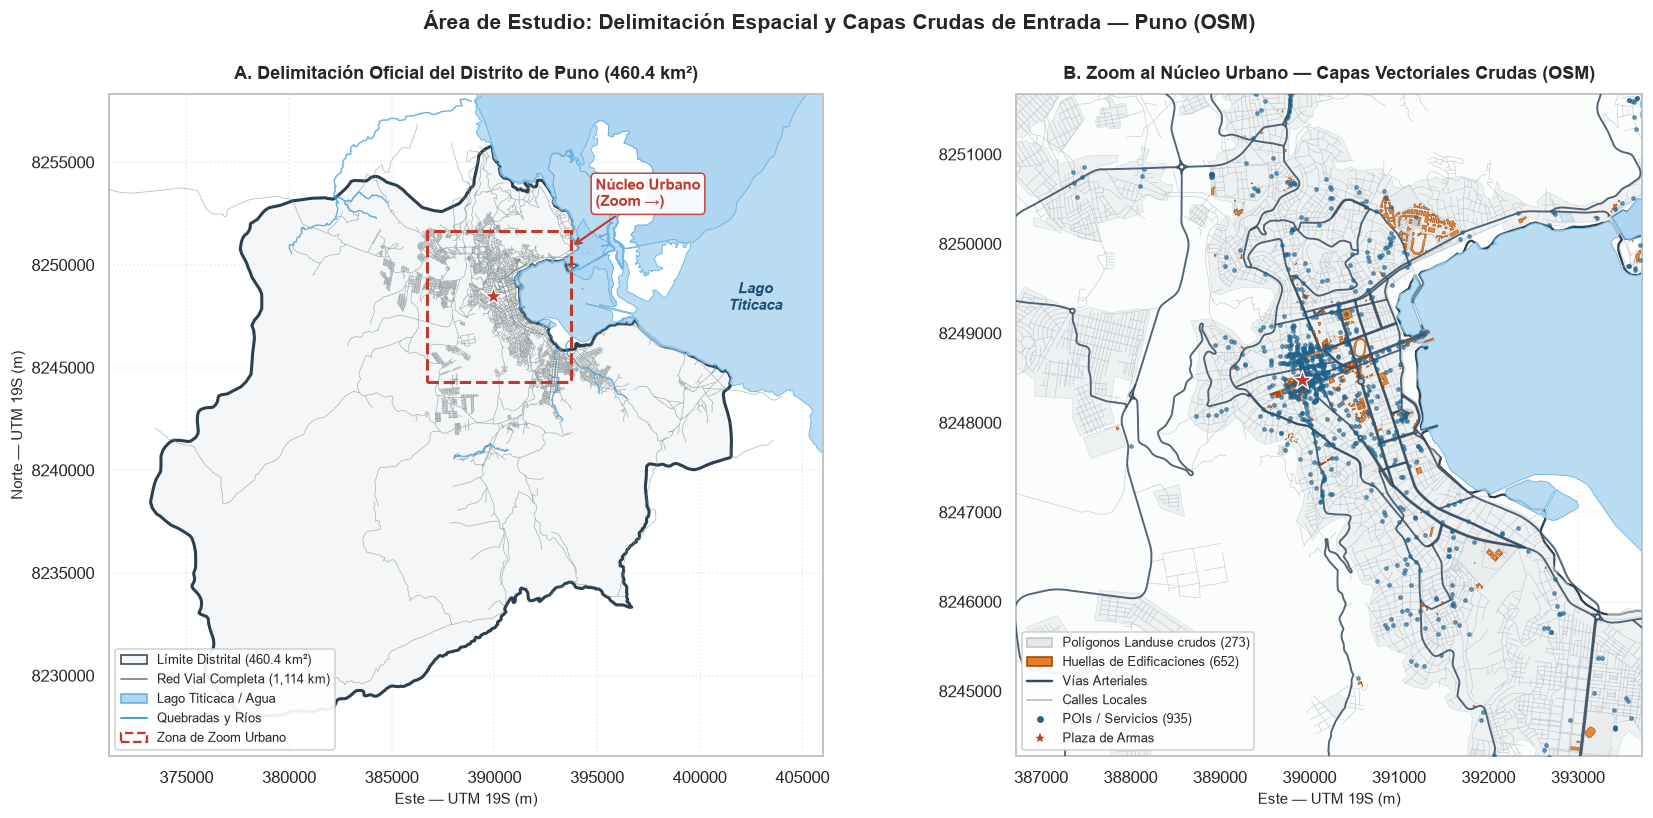

Figura guardada en: figures/01_mapa_cartografico_puno.png


In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7.5), gridspec_kw={'width_ratios': [1.05, 1]})

px, py = plaza_armas_utm.x, plaza_armas_utm.y
zoom_minx, zoom_maxx = px - 3200, px + 3800
zoom_miny, zoom_maxy = py - 4200, py + 3200

# --- PANEL IZQUIERDO: DISTRITO COMPLETO DE PUNO (DELIMITACIÓN CRUDA) ---
puno_utm.plot(ax=ax1, color='#f4f6f7', edgecolor='#2c3e50', linewidth=2.0, zorder=1)
wa_utm.plot(ax=ax1, color='#aed6f1', edgecolor='#5dade2', linewidth=0.6, alpha=0.85, zorder=2)
ww_utm.plot(ax=ax1, color='#3498db', linewidth=0.9, alpha=0.75, zorder=3)
rd_utm.plot(ax=ax1, color='#7f8c8d', linewidth=0.45, alpha=0.65, zorder=4)

rect_zoom = Rectangle(
    (zoom_minx, zoom_miny), zoom_maxx - zoom_minx, zoom_maxy - zoom_miny,
    linewidth=2.0, edgecolor='#c0392b', facecolor='none', linestyle='--', zorder=6
)
ax1.add_patch(rect_zoom)
ax1.scatter([px], [py], color='#c0392b', marker='*', s=150, edgecolor='white', linewidth=0.8, zorder=7)

bminx, bminy, bmaxx, bmaxy = puno_utm.total_bounds
ax1.set_xlim(bminx - 2000, bmaxx + 4500)
ax1.set_ylim(bminy - 2000, bmaxy + 2500)

ax1.annotate("Núcleo Urbano\n(Zoom →)", xy=(zoom_maxx, zoom_maxy - 800),
             xytext=(zoom_maxx + 1200, zoom_maxy + 1200),
             fontsize=9.5, fontweight='bold', color='#c0392b',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#c0392b', alpha=0.92),
             arrowprops=dict(arrowstyle='->', color='#c0392b', lw=1.4))
ax1.text(bmaxx + 1200, bmaxy - 8000, "Lago\nTiticaca", fontsize=10, style='italic',
         fontweight='bold', color='#1b4f72', ha='center', zorder=7)

ax1.set_title(f"A. Delimitación Oficial del Distrito de Puno ({area_km2:,.1f} km²)", pad=10)
ax1.set_xlabel("Este — UTM 19S (m)")
ax1.set_ylabel("Norte — UTM 19S (m)")
ax1.ticklabel_format(style='plain', axis='both')
ax1.grid(True, linestyle=':', alpha=0.4)

handles_a = [
    mpatches.Patch(facecolor='#f4f6f7', edgecolor='#2c3e50', label='Límite Distrital (460.4 km²)'),
    plt.Line2D([0], [0], color='#7f8c8d', lw=1.2, label='Red Vial Completa (1,114 km)'),
    mpatches.Patch(facecolor='#aed6f1', edgecolor='#5dade2', label='Lago Titicaca / Agua'),
    plt.Line2D([0], [0], color='#3498db', lw=1.2, label='Quebradas y Ríos'),
    mpatches.Patch(facecolor='none', edgecolor='#c0392b', linestyle='--', linewidth=1.5, label='Zona de Zoom Urbano')
]
ax1.legend(handles=handles_a, loc='lower left', fontsize=8.5, frameon=True, facecolor='white', framealpha=0.92)

# --- PANEL DERECHO: ZOOM AL NÚCLEO URBANO (GEOMETRÍAS CRUDAS OSM SIN CLASIFICAR) ---
puno_utm.plot(ax=ax2, color='#fbfcfc', edgecolor='#2c3e50', linewidth=1.5, zorder=1)
wa_utm.plot(ax=ax2, color='#aed6f1', edgecolor='#5dade2', linewidth=0.6, alpha=0.85, zorder=2)
lu_utm.plot(ax=ax2, color='#e5e8e8', edgecolor='#bdc3c7', linewidth=0.4, alpha=0.55, zorder=2)

vias_art = {'trunk', 'primary', 'primary_link', 'secondary', 'secondary_link', 'tertiary', 'tertiary_link'}
rd_utm[~rd_utm['fclass'].isin(vias_art)].plot(ax=ax2, color='#aeb6bf', linewidth=0.45, alpha=0.65, zorder=4)
rd_utm[rd_utm['fclass'].isin(vias_art)].plot(ax=ax2, color='#34495e', linewidth=1.25, alpha=0.85, zorder=5)

b_utm.plot(ax=ax2, color='#e67e22', edgecolor='#a04000', linewidth=0.35, alpha=0.9, zorder=6)
p_utm.plot(ax=ax2, color='#1f618d', markersize=5, alpha=0.55, zorder=7)
ax2.scatter([px], [py], color='#c0392b', marker='*', s=180, edgecolor='white', linewidth=0.9, zorder=8)

ax2.set_xlim(zoom_minx, zoom_maxx)
ax2.set_ylim(zoom_miny, zoom_maxy)
ax2.set_title("B. Zoom al Núcleo Urbano — Capas Vectoriales Crudas (OSM)", pad=10)
ax2.set_xlabel("Este — UTM 19S (m)")
ax2.set_ylabel("")
ax2.ticklabel_format(style='plain', axis='both')
ax2.grid(True, linestyle=':', alpha=0.4)

handles_b = [
    mpatches.Patch(facecolor='#e5e8e8', edgecolor='#bdc3c7', label='Polígonos Landuse crudos (273)'),
    mpatches.Patch(facecolor='#e67e22', edgecolor='#a04000', label=f'Huellas de Edificaciones ({len(b_utm)})'),
    plt.Line2D([0], [0], color='#34495e', lw=1.6, label='Vías Arteriales'),
    plt.Line2D([0], [0], color='#aeb6bf', lw=1.0, label='Calles Locales'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#1f618d', markersize=5.5, label=f'POIs / Servicios ({len(p_utm)})'),
    plt.Line2D([0], [0], marker='*', color='w', markerfacecolor='#c0392b', markersize=10, label='Plaza de Armas')
]
ax2.legend(handles=handles_b, loc='lower left', fontsize=8.2, frameon=True, facecolor='white', framealpha=0.93)

plt.suptitle("Área de Estudio: Delimitación Espacial y Capas Crudas de Entrada — Puno (OSM)", fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "01_mapa_cartografico_puno.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/01_mapa_cartografico_puno.png")